# 01. Análise exploratória e preparação dos dados

Base **AI4I 2020 Predictive Maintenance** (UCI). Descreve a base, justifica a limpeza e o balanceamento e gera os conjuntos usados nas Etapas I e II.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # comandos python -m src.* rodam a partir da raiz
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from src import config as C
pd.set_option("display.max_columns", 30)

## 1. Carga e visão geral

In [2]:
from src.data import load_raw, clean
raw = load_raw()
print(raw.shape)
raw.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,10000.0,5000.50000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.30,300.1,301.50,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.80,310.1,311.10,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.00,1503.0,1612.00,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.20,40.1,46.80,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.00,108.0,162.00,253.0
Machine failure,10000.0,0.03390,0.180981,0.0,0.00,0.0,0.00,1.0
TWF,10000.0,0.00460,0.067671,0.0,0.00,0.0,0.00,1.0
HDF,10000.0,0.01150,0.106625,0.0,0.00,0.0,0.00,1.0
PWF,10000.0,0.00950,0.097009,0.0,0.00,0.0,0.00,1.0


## 2. Exemplos da base

Dois casos normais e um de falha.

In [5]:
cols = C.CATEGORICAL_COLS + C.NUMERIC_COLS + [C.TARGET]
exemplos = pd.concat([raw[raw[C.TARGET] == 0].sample(2, random_state=C.SEED), raw[raw[C.TARGET] == 1].sample(1, random_state=C.SEED)])
exemplos[cols]

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
6130,L,301.0,310.9,1473,44.2,116,0
9063,L,297.2,308.3,1419,39.7,115,0
7509,L,300.6,311.9,1372,60.1,212,1


## 3. Valor desejado e desbalanceamento

Machine failure
0    9661
1     339
Name: count, dtype: int64 
proporção de falhas: 3.39%


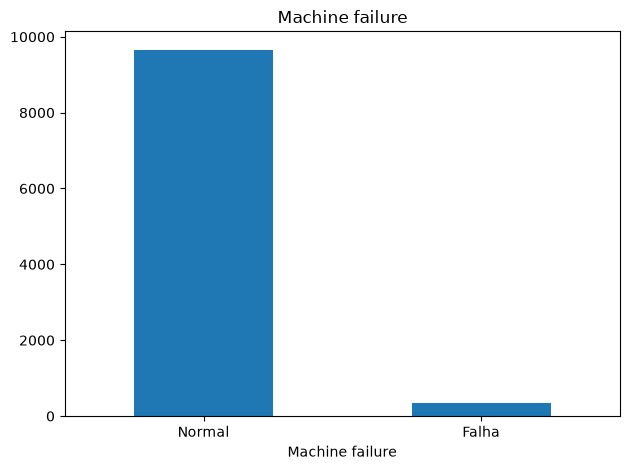

In [6]:
contagem = raw[C.TARGET].value_counts()
print(contagem, f"\nproporção de falhas: {raw[C.TARGET].mean():.2%}")
ax = contagem.rename({0: 'Normal', 1: 'Falha'}).plot.bar(rot=0, title='Machine failure')
plt.tight_layout(); plt.savefig(C.FIGURES / 'eda_target.png', dpi=150); plt.show()

Um classificador que sempre responde "normal" acerta ~96,6%: por isso a acurácia sozinha não serve e o foco é **F1 e revocação** da classe falha.

## 4. Modos de falha e vazamento

TWF, HDF, PWF, OSF e RNF dizem *qual* falha ocorreu. Eles só valem 1 quando há falha, então usá-los como entrada seria vazamento: saem dos atributos.

In [7]:
modos = raw[C.FAILURE_MODE_COLS].sum().sort_values(ascending=False)
print(modos)
qualquer_modo = raw[C.FAILURE_MODE_COLS].max(axis=1)
pd.crosstab(raw[C.TARGET], qualquer_modo, rownames=['Machine failure'], colnames=['algum modo = 1'])

HDF    115
OSF     98
PWF     95
TWF     46
RNF     19
dtype: int64


algum modo = 1,0,1
Machine failure,,
0,9643,18
1,9,330


Há casos com `Machine failure = 1` sem nenhum modo marcado e casos com RNF = 1 e `Machine failure = 0`. É um ruído conhecido da base.

## 5. Distribuição dos atributos por classe

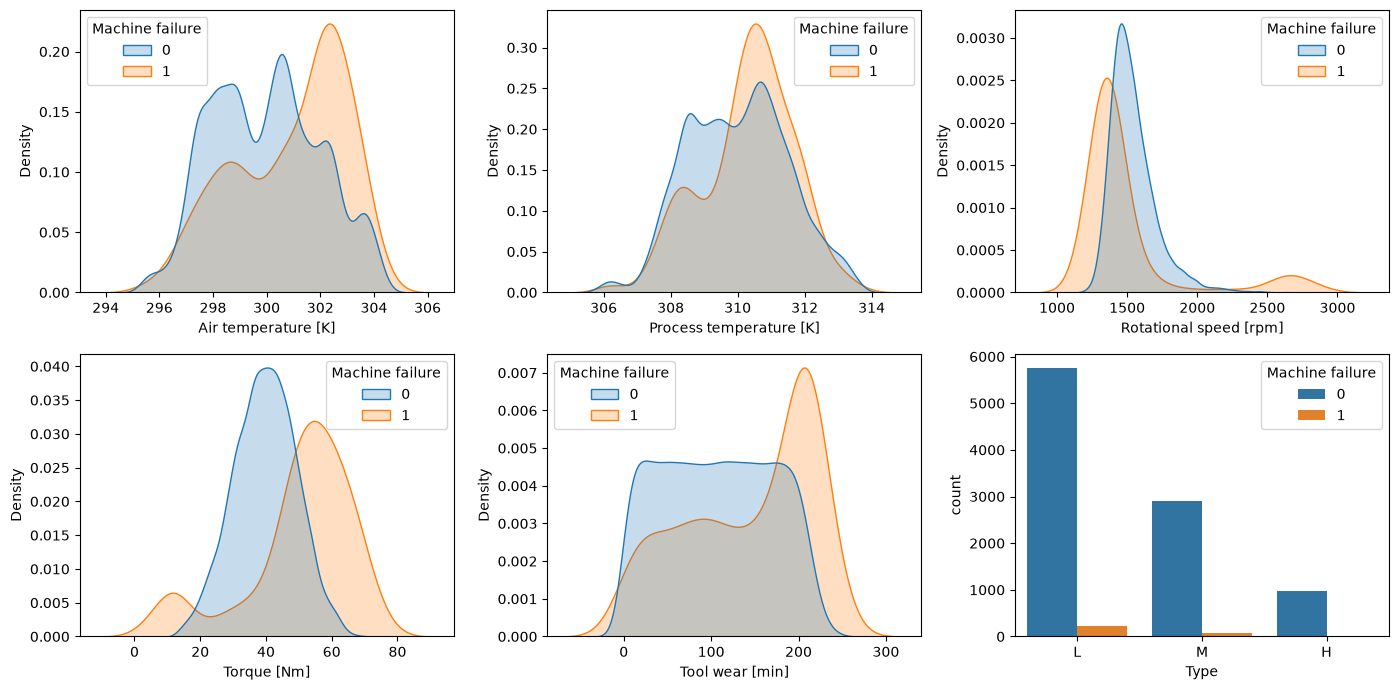

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flat, C.NUMERIC_COLS):
    sns.kdeplot(data=raw, x=col, hue=C.TARGET, common_norm=False, fill=True, ax=ax)
sns.countplot(data=raw, x='Type', hue=C.TARGET, ax=axes.flat[-1], order=['L', 'M', 'H'])
plt.tight_layout(); plt.savefig(C.FIGURES / 'eda_distribuicoes.png', dpi=150); plt.show()

In [9]:
pd.crosstab(raw['Type'], raw[C.TARGET], normalize='index').style.format('{:.2%}')

Machine failure,0,1
Type,,
H,97.91%,2.09%
L,96.08%,3.92%
M,97.23%,2.77%


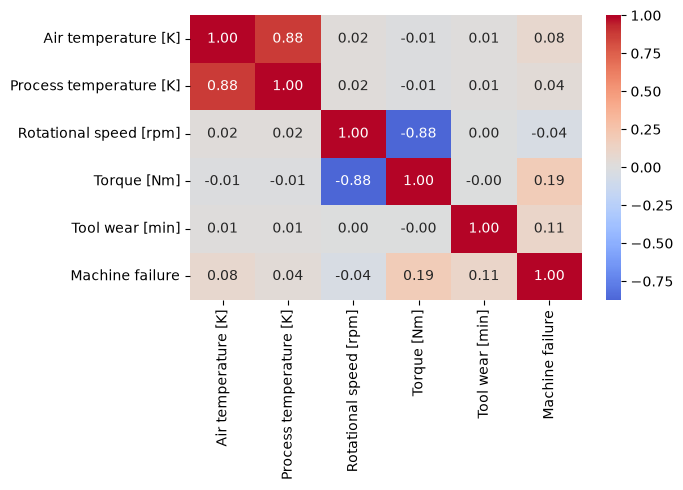

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(raw[C.NUMERIC_COLS + [C.TARGET]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.tight_layout(); plt.savefig(C.FIGURES / 'eda_correlacao.png', dpi=150); plt.show()

## 6. Limpeza

Verificação de nulos e duplicatas. A base é sintética e vem limpa.

In [11]:
print('nulos:', raw.isna().sum().sum(), '| UDI duplicados:', raw['UDI'].duplicated().sum())
df = clean(raw)

nulos: 0 | UDI duplicados: 0


## 7. Atributos derivados (opcional)

A documentação da base descreve as regras das falhas em termos de diferença de temperatura, potência e desgaste x torque. O baseline não usa esses atributos; a variação com eles roda com `python -m src.train_classical --engineered`.

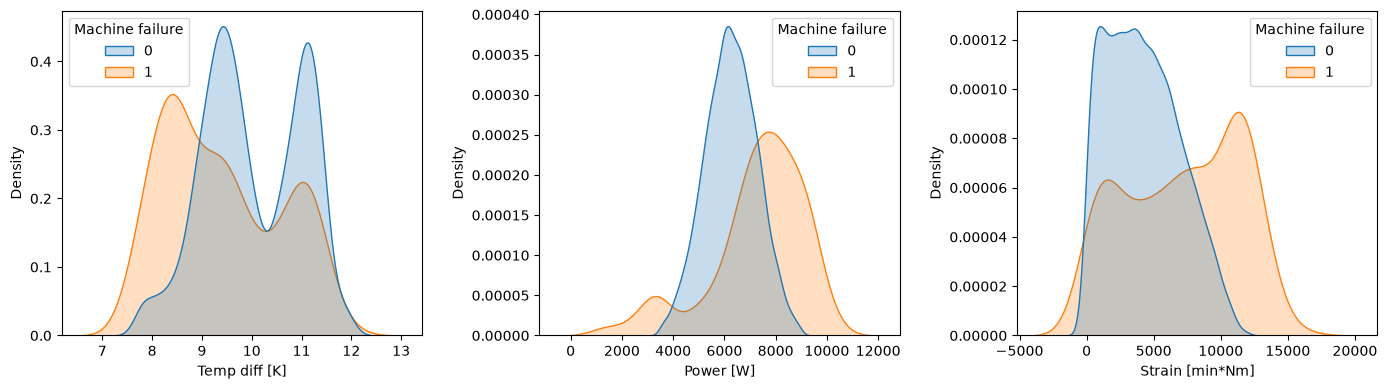

In [12]:
from src.data import add_engineered_features
eng = add_engineered_features(df)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['Temp diff [K]', 'Power [W]', 'Strain [min*Nm]']):
    sns.kdeplot(data=eng, x=col, hue=C.TARGET, common_norm=False, fill=True, ax=ax)
plt.tight_layout(); plt.show()

## 8. Divisão dos conjuntos e amostra fixa

- 80/20 estratificado, semente 42
- Normalização (z-score) e balanceamento (SMOTE) **não** são aplicados aqui: ficam dentro do pipeline de cada modelo, ajustados só no treino
- Amostra fixa de 200 casos do teste (50 falhas + 150 normais) para comparar com o LLM

In [13]:
from src.data import prepare, summary
parts = prepare(save=True)
summary(parts)

train        n= 8000  falhas= 271 (3.4%)
test         n= 2000  falhas=  68 (3.4%)
eval_sample  n=  200  falhas=  50 (25.0%)


## 9. Efeito do SMOTE (ilustração)

In [14]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler
X = StandardScaler().fit_transform(parts['train'][C.NUMERIC_COLS])
y = parts['train'][C.TARGET]
Xs, ys = SMOTE(random_state=C.SEED).fit_resample(X, y)
print('antes :', y.value_counts().to_dict())
print('depois:', pd.Series(ys).value_counts().to_dict())

antes : {0: 7729, 1: 271}
depois: {0: 7729, 1: 7729}
